In [ ]:
import numpy as np
import pandas as pd

# For reproducible results
np.random.seed(42)

records = []

zones = {
    "A": {"start": 300, "trend": 8},    # Normal growth
    "B": {"start": 500, "trend": 15},   # Increasing
    "C": {"start": 400, "trend": 25},   # Dange
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    
    rous surge
    "D": {"start": 1500, "trend": -12}  # Decreasing
}

# Create 200 time steps for each zone
for zone, info in zones.items():

    crowd = info["start"]

    for t in range(200):

        # Add normal random variation
        noise = np.random.randint(-30, 31)

        # Zone C gets a sudden surge after time step 80
        surge = 0
        if zone == "C" and t > 80:
            surge = (t - 80) * 8

        # Update crowd count
        crowd = max(50, crowd + info["trend"] + noise + surge * 0.02)

        # Simulated entry and exit rates
        entry_rate = max(0, int(np.random.normal(60, 15)))
        exit_rate = max(0, int(np.random.normal(50, 12)))

        # Movement speed decreases when crowd becomes dense
        movement_speed = max(
            0.2,
            round(1.5 - (crowd / 3000) + np.random.normal(0, 0.1), 2)
        )

        # Assume each zone has area = 500 square meters
        density = round(crowd / 500, 2)

        # Risk classification
        if density < 2:
            risk = "Safe"
        elif density < 3:
            risk = "Warning"
        elif density < 4:
            risk = "High"
        else:
            risk = "Critical"

        records.append({
            "time_step": t,
            "zone": zone,
            "crowd_count": int(crowd),
            "entry_rate": entry_rate,
            "exit_rate": exit_rate,
            "movement_speed": movement_speed,
            "density": density,
            "risk": risk
        })

# Create DataFrame
df = pd.DataFrame(records)

# Display first 10 rows
df.head(10)

,time_step,zone,crowd_count,entry_rate,exit_rate,movement_speed,density,risk
0,0,A,316,51,56,1.44,0.63,Safe
1,1,A,351,80,53,1.48,0.70,Safe
2,2,A,352,52,51,1.41,0.70,Safe
3,3,A,331,61,44,1.34,0.66,Safe
4,4,A,320,60,44,1.34,0.64,Safe
5,5,A,357,58,41,1.17,0.71,Safe
6,6,A,381,37,67,1.37,0.76,Safe
7,7,A,395,65,36,1.41,0.79,Safe
8,8,A,411,29,63,1.44,0.82,Safe
9,9,A,432,43,43,1.36,0.86,Safe


In [ ]:
df.to_csv("crowdshield_dataset.csv", index=False)

print("Dataset created successfully!")
print("Total records:", len(df))
print("\nRecords per zone:")
print(df["zone"].value_counts())

print("\nRisk distribution:")
print(df["risk"].value_counts())

Dataset created successfully!
Total records: 800

Records per zone:
zone
A    200
B    200
C    200
D    200
Name: count, dtype: int64

Risk distribution:
risk
Safe        292
Critical    261
Warning     140
High        107
Name: count, dtype: int64


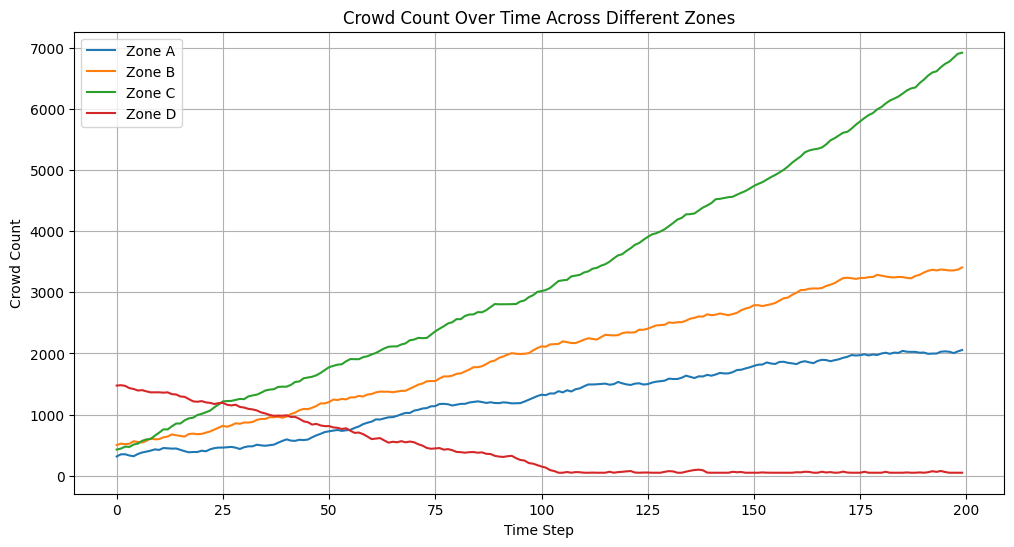

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for zone in df["zone"].unique():
    zone_data = df[df["zone"] == zone]
    plt.plot(
        zone_data["time_step"],
        zone_data["crowd_count"],
        label=f"Zone {zone}"
    )

plt.title("Crowd Count Over Time Across Different Zones")
plt.xlabel("Time Step")
plt.ylabel("Crowd Count")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Let's use one zone first: Zone A
zone_a = df[df["zone"] == "A"].copy()

# Get crowd counts
crowd_values = zone_a["crowd_count"].values

# Number of past values used to predict the next value
sequence_length = 5

X = []
y = []

for i in range(len(crowd_values) - sequence_length):
    # Previous 5 values
    X.append(crowd_values[i:i + sequence_length])

    # Next value to predict
    y.append(crowd_values[i + sequence_length])

# Convert to NumPy arrays
X = np.array(X)
y = np.array(y)

print("Input sequences shape:", X.shape)
print("Target values shape:", y.shape)

print("\nFirst input sequence:")
print(X[0])

print("\nFirst target:")
print(y[0])

Input sequences shape: (195, 5)
Target values shape: (195,)

First input sequence:
[316 351 352 331 320]

First target:
357


In [ ]:
# Use the first 80% for training
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)

print("\nTraining targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training sequences: (156, 5)
Testing sequences: (39, 5)

Training targets: (156,)
Testing targets: (39,)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Create the scaler
scaler = MinMaxScaler()

# Fit ONLY on training crowd values
X_train_scaled = scaler.fit_transform(X_train.reshape(-1, 1)).reshape(X_train.shape)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test.reshape(-1, 1)).reshape(X_test.shape)

# Scale target values too
y_train_scaled = scaler.transform(y_train.reshape(-1, 1)).flatten()
y_test_scaled = scaler.transform(y_test.reshape(-1, 1)).flatten()

print("First original training sequence:")
print(X_train[0])

print("\nFirst scaled training sequence:")
print(X_train_scaled[0])

print("\nFirst original target:", y_train[0])
print("First scaled target:", y_train_scaled[0])

First original training sequence:
[316 351 352 331 320]

First scaled training sequence:
[0.         0.02260982 0.02325581 0.00968992 0.00258398]

First original target: 357
First scaled target: 0.02648578811369509


In [ ]:
# Reservoir settings
reservoir_size = 50
np.random.seed(42)

# Random input weights: Input -> Reservoir
Win = np.random.uniform(
    -0.5, 0.5,
    (reservoir_size, sequence_length)
)

# Random reservoir weights: Previous State -> New State
W = np.random.uniform(
    -0.5, 0.5,
    (reservoir_size, reservoir_size)
)

# Function to get reservoir states
def get_reservoir_states(X_data):

    all_states = []

    # Process every input sequence
    for sequence in X_data:

        # Start with an empty reservoir memory
        state = np.zeros(reservoir_size)

        # Send the sequence values one by one
        for value in sequence:

            # Input vector
            input_vector = np.full(sequence_length, value)

            # Update reservoir state
            state = np.tanh(
                Win @ input_vector + W @ state
            )

        # Save the final state for this sequence
        all_states.append(state)

    return np.array(all_states)


# Create reservoir states for training and testing data
train_states = get_reservoir_states(X_train_scaled)
test_states = get_reservoir_states(X_test_scaled)

print("Training reservoir states shape:", train_states.shape)
print("Testing reservoir states shape:", test_states.shape)

Training reservoir states shape: (156, 50)
Testing reservoir states shape: (39, 50)


In [ ]:
from sklearn.linear_model import Ridge

# Create the readout model
readout = Ridge(alpha=0.1)

# Train the readout using reservoir states
readout.fit(train_states, y_train_scaled)

# Predict crowd values
y_pred_scaled = readout.predict(test_states)

# Convert predictions back to original crowd counts
y_pred = scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).flatten()

# Display first 10 predictions
print("Actual vs Predicted Crowd Count:\n")

for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(
        f"Actual: {actual} | Predicted: {predicted:.2f}"
    )

Actual vs Predicted Crowd Count:

Actual: 1859 | Predicted: 1816.44
Actual: 1873 | Predicted: 1821.85
Actual: 1855 | Predicted: 1841.98
Actual: 1841 | Predicted: 1842.86
Actual: 1878 | Predicted: 1829.49
Actual: 1896 | Predicted: 1834.04
Actual: 1892 | Predicted: 1856.93
Actual: 1873 | Predicted: 1864.06
Actual: 1890 | Predicted: 1855.12
Actual: 1905 | Predicted: 1850.87


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate errors
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("CLASSICAL RESERVOIR COMPUTING RESULTS")
print("--------------------------------------")
print(f"MAE  : {mae:.2f} people")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} people")

CLASSICAL RESERVOIR COMPUTING RESULTS
--------------------------------------
MAE  : 66.08 people
MSE  : 4986.58
RMSE : 70.62 people


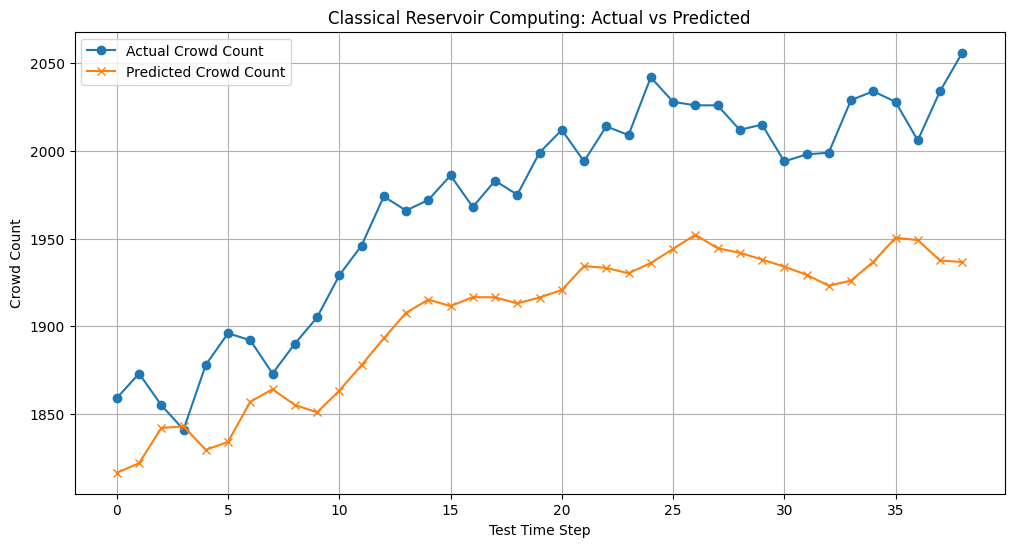

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test, label="Actual Crowd Count", marker="o")
plt.plot(y_pred, label="Predicted Crowd Count", marker="x")

plt.title("Classical Reservoir Computing: Actual vs Predicted")
plt.xlabel("Test Time Step")
plt.ylabel("Crowd Count")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
!pip install qiskit

In [ ]:
import qiskit

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.5.2


In [ ]:
!pip install matplotlib-venn

In [ ]:
!pip install pylatexenc

In [ ]:
import numpy as np
from qiskit import QuantumCircuit

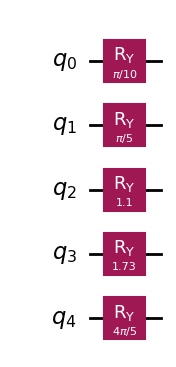

In [ ]:
# Example crowd data
crowd_sequence = [0.10, 0.20, 0.35, 0.55, 0.80]

# Create 5 qubits
qc = QuantumCircuit(5)

# Encode each crowd value using RY rotation
for i, value in enumerate(crowd_sequence):
    angle = value * np.pi
    qc.ry(angle, i)

# Draw the circuit
qc.draw("mpl")

In [ ]:
from qiskit import QuantumCircuit
import numpy as np

# Example crowd sequence
crowd_sequence = [0.10, 0.20, 0.35, 0.55, 0.80]

# Create 5-qubit circuit
qc = QuantumCircuit(5)

# STEP 1: Encode crowd data
for i, value in enumerate(crowd_sequence):
    qc.ry(value * np.pi, i)

# STEP 2: Quantum Reservoir
# Fixed rotations
for i in range(5):
    qc.rz(0.7, i)
    qc.rx(0.4, i)

# Entangle neighbouring qubits
for i in range(4):
    qc.cx(i, i + 1)

# Display circuit
print(qc.draw())

      ┌──────────┐ ┌─────────┐┌─────────┐                    
q_0: ─┤ Ry(π/10) ├─┤ Rz(0.7) ├┤ Rx(0.4) ├──■─────────────────
      ├─────────┬┘ ├─────────┤├─────────┤┌─┴─┐               
q_1: ─┤ Ry(π/5) ├──┤ Rz(0.7) ├┤ Rx(0.4) ├┤ X ├──■────────────
     ┌┴─────────┴─┐├─────────┤├─────────┤└───┘┌─┴─┐          
q_2: ┤ Ry(1.0996) ├┤ Rz(0.7) ├┤ Rx(0.4) ├─────┤ X ├──■───────
     ├────────────┤├─────────┤├─────────┤     └───┘┌─┴─┐     
q_3: ┤ Ry(1.7279) ├┤ Rz(0.7) ├┤ Rx(0.4) ├──────────┤ X ├──■──
     └┬──────────┬┘├─────────┤├─────────┤          └───┘┌─┴─┐
q_4: ─┤ Ry(4π/5) ├─┤ Rz(0.7) ├┤ Rx(0.4) ├───────────────┤ X ├
      └──────────┘ └─────────┘└─────────┘               └───┘


In [ ]:
from qiskit.quantum_info import Statevector, SparsePauliOp
import numpy as np

# Get the final quantum state
state = Statevector.from_instruction(qc)

quantum_features = []

# Calculate Z expectation value for each qubit
for i in range(5):
    # Create a Z observable for the selected qubit
    pauli_string = ["I"] * 5
    pauli_string[4 - i] = "Z"   # Qiskit's qubit ordering

    observable = SparsePauliOp("".join(pauli_string))

    # Extract expectation value
    expectation = np.real(state.expectation_value(observable))
    quantum_features.append(expectation)

print("Quantum Features:")
print(np.array(quantum_features))

Quantum Features:
[ 0.95350421  0.8511091   0.54613961  0.05663242 -0.03384898]


In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
import numpy as np

# Number of qubits = number of past crowd values
n_qubits = 5

def quantum_reservoir_features(sequence):

    # Create a fresh quantum circuit
    qc = QuantumCircuit(n_qubits)

    # STEP 1: Encode crowd data
    for i, value in enumerate(sequence):
        qc.ry(value * np.pi, i)

    # STEP 2: Fixed Quantum Reservoir
    for i in range(n_qubits):
        qc.rz(0.7, i)
        qc.rx(0.4, i)

    # Entangle neighbouring qubits
    for i in range(n_qubits - 1):
        qc.cx(i, i + 1)

    # STEP 3: Get final quantum state
    state = Statevector.from_instruction(qc)

    # STEP 4: Extract Z expectation values
    features = []

    for i in range(n_qubits):
        pauli_string = ["I"] * n_qubits
        pauli_string[n_qubits - 1 - i] = "Z"

        observable = SparsePauliOp("".join(pauli_string))

        expectation = np.real(
            state.expectation_value(observable)
        )

        features.append(expectation)

    return features

In [ ]:
test_features = quantum_reservoir_features(X_train_scaled[0])

print("Input sequence:")
print(X_train_scaled[0])

print("\nQuantum features:")
print(test_features)

print("\nNumber of features:", len(test_features))

Input sequence:
[0.         0.02260982 0.02325581 0.00968992 0.00258398]

Quantum features:
[np.float64(0.9210609940028843), np.float64(0.8626131886560829), np.float64(0.8081962816126211), np.float64(0.7502243703987141), np.float64(0.6925074639270317)]

Number of features: 5


In [ ]:
# Process all training sequences through the Quantum Reservoir
quantum_train_features = np.array([
    quantum_reservoir_features(sequence)
    for sequence in X_train_scaled
])

# Process all testing sequences through the Quantum Reservoir
quantum_test_features = np.array([
    quantum_reservoir_features(sequence)
    for sequence in X_test_scaled
])

print("Quantum training features shape:", quantum_train_features.shape)
print("Quantum testing features shape:", quantum_test_features.shape)

print("\nFirst training quantum features:")
print(quantum_train_features[0])

Quantum training features shape: (156, 5)
Quantum testing features shape: (39, 5)

First training quantum features:
[0.92106099 0.86261319 0.80819628 0.75022437 0.69250746]


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create Quantum readout model
quantum_readout = Ridge(alpha=0.1)

# Train using Quantum Reservoir features
quantum_readout.fit(
    quantum_train_features,
    y_train_scaled
)

# Predict scaled crowd values
quantum_y_pred_scaled = quantum_readout.predict(
    quantum_test_features
)

# Convert predictions back to actual crowd counts
quantum_y_pred = scaler.inverse_transform(
    quantum_y_pred_scaled.reshape(-1, 1)
).flatten()

# Calculate performance
quantum_mae = mean_absolute_error(y_test, quantum_y_pred)
quantum_mse = mean_squared_error(y_test, quantum_y_pred)
quantum_rmse = np.sqrt(quantum_mse)

print("QUANTUM RESERVOIR COMPUTING RESULTS")
print("-----------------------------------")
print(f"MAE  : {quantum_mae:.2f} people")
print(f"MSE  : {quantum_mse:.2f}")
print(f"RMSE : {quantum_rmse:.2f} people")

QUANTUM RESERVOIR COMPUTING RESULTS
-----------------------------------
MAE  : 51.90 people
MSE  : 3630.90
RMSE : 60.26 people


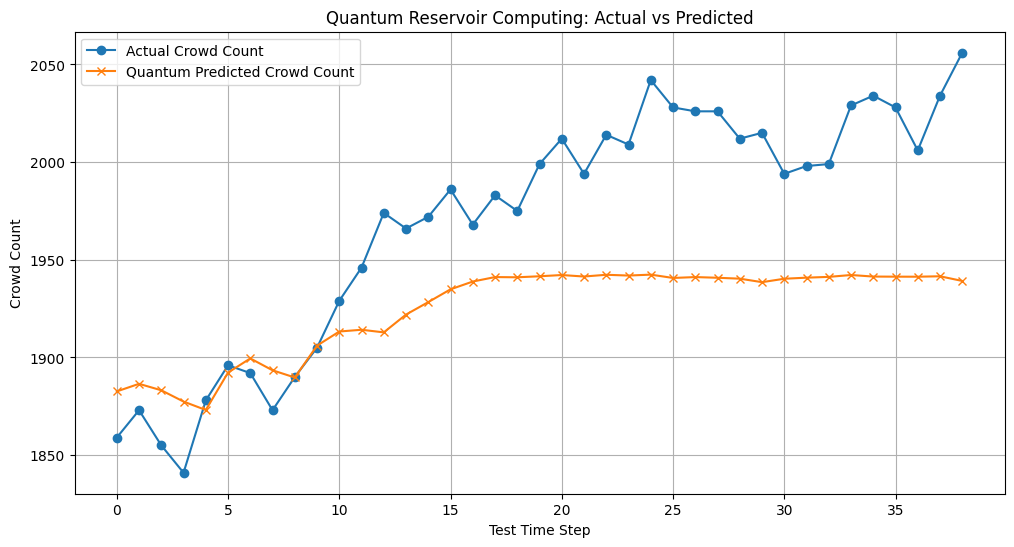

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(y_test, label="Actual Crowd Count", marker="o")
plt.plot(quantum_y_pred, label="Quantum Predicted Crowd Count", marker="x")

plt.title("Quantum Reservoir Computing: Actual vs Predicted")
plt.xlabel("Test Time Step")
plt.ylabel("Crowd Count")
plt.legend()
plt.grid(True)

plt.show()

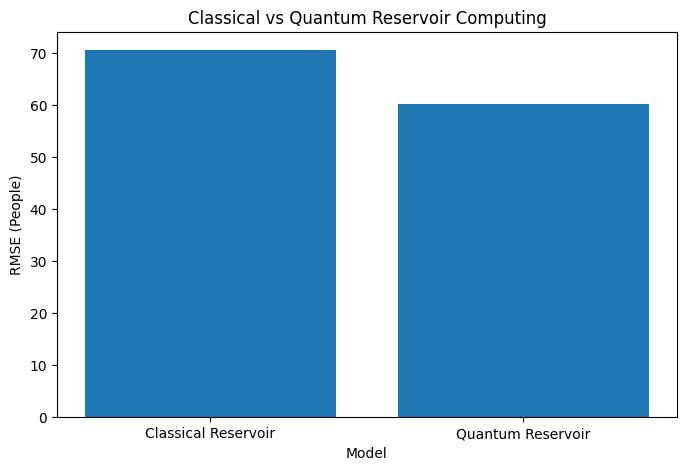

In [ ]:
models = ["Classical Reservoir", "Quantum Reservoir"]
rmse_values = [70.62, 60.26]

plt.figure(figsize=(8, 5))

plt.bar(models, rmse_values)

plt.title("Classical vs Quantum Reservoir Computing")
plt.xlabel("Model")
plt.ylabel("RMSE (People)")

plt.show()

In [ ]:
def get_risk_level(crowd_count):

    if crowd_count < 800:
        return "SAFE"

    elif crowd_count < 1200:
        return "WARNING"

    elif crowd_count < 1600:
        return "HIGH"

    else:
        return "CRITICAL"


# Test the alert system
test_counts = [450, 950, 1400, 1900]

for count in test_counts:
    print(f"Crowd Count: {count} → Risk Level: {get_risk_level(count)}")

Crowd Count: 450 → Risk Level: SAFE
Crowd Count: 950 → Risk Level: WARNING
Crowd Count: 1400 → Risk Level: HIGH
Crowd Count: 1900 → Risk Level: CRITICAL


In [ ]:
print("QUANTUM CROWDSHIELD ALERT SYSTEM")
print("=" * 45)

for i in range(10):
    predicted_count = quantum_y_pred[i]
    actual_count = y_test[i]

    risk = get_risk_level(predicted_count)

    print(f"\nTime Step {i+1}")
    print(f"Actual Crowd:    {actual_count}")
    print(f"Predicted Crowd: {predicted_count:.0f}")
    print(f"Risk Alert:      {risk}")

QUANTUM CROWDSHIELD ALERT SYSTEM

Time Step 1
Actual Crowd:    1859
Predicted Crowd: 1883
Risk Alert:      CRITICAL

Time Step 2
Actual Crowd:    1873
Predicted Crowd: 1887
Risk Alert:      CRITICAL

Time Step 3
Actual Crowd:    1855
Predicted Crowd: 1883
Risk Alert:      CRITICAL

Time Step 4
Actual Crowd:    1841
Predicted Crowd: 1877
Risk Alert:      CRITICAL

Time Step 5
Actual Crowd:    1878
Predicted Crowd: 1873
Risk Alert:      CRITICAL

Time Step 6
Actual Crowd:    1896
Predicted Crowd: 1892
Risk Alert:      CRITICAL

Time Step 7
Actual Crowd:    1892
Predicted Crowd: 1900
Risk Alert:      CRITICAL

Time Step 8
Actual Crowd:    1873
Predicted Crowd: 1893
Risk Alert:      CRITICAL

Time Step 9
Actual Crowd:    1890
Predicted Crowd: 1890
Risk Alert:      CRITICAL

Time Step 10
Actual Crowd:    1905
Predicted Crowd: 1906
Risk Alert:      CRITICAL


In [ ]:
def get_recommended_action(risk_level):

    if risk_level == "SAFE":
        return "Normal monitoring. No immediate action required."

    elif risk_level == "WARNING":
        return "Increase monitoring and prepare crowd management teams."

    elif risk_level == "HIGH":
        return "Control entry, deploy additional staff, and prepare alternate routes."

    elif risk_level == "CRITICAL":
        return "Immediate action: Restrict entry, redirect the crowd, open emergency exits, and alert authorities."


print("CROWDSHIELD PUBLIC SAFETY RECOMMENDATIONS")
print("=" * 55)

for i in range(10):
    predicted_count = quantum_y_pred[i]
    risk = get_risk_level(predicted_count)
    action = get_recommended_action(risk)

    print(f"\nTime Step {i+1}")
    print(f"Predicted Crowd: {predicted_count:.0f}")
    print(f"Risk Level: {risk}")
    print(f"Recommended Action: {action}")

CROWDSHIELD PUBLIC SAFETY RECOMMENDATIONS

Time Step 1
Predicted Crowd: 1883
Risk Level: CRITICAL
Recommended Action: Immediate action: Restrict entry, redirect the crowd, open emergency exits, and alert authorities.

Time Step 2
Predicted Crowd: 1887
Risk Level: CRITICAL
Recommended Action: Immediate action: Restrict entry, redirect the crowd, open emergency exits, and alert authorities.

Time Step 3
Predicted Crowd: 1883
Risk Level: CRITICAL
Recommended Action: Immediate action: Restrict entry, redirect the crowd, open emergency exits, and alert authorities.

Time Step 4
Predicted Crowd: 1877
Risk Level: CRITICAL
Recommended Action: Immediate action: Restrict entry, redirect the crowd, open emergency exits, and alert authorities.

Time Step 5
Predicted Crowd: 1873
Risk Level: CRITICAL
Recommended Action: Immediate action: Restrict entry, redirect the crowd, open emergency exits, and alert authorities.

Time Step 6
Predicted Crowd: 1892
Risk Level: CRITICAL
Recommended Action: Immedia